# 03 · Caracterización del alfa y evolución temporal

**Proyecto final · Reactividad alfa en EEG durante la alternancia de ojos abiertos y cerrados**

| | |
|---|---|
| Dueño | C · Diego |
| Etapas de la rúbrica | Etapas 3 y 4 (20 %) |
| Entregable técnico | `potencia_alfa()`, `resumen_por_bloque()` |
| Figuras | fig03_psd_eo_vs_ec · fig04_alfa_en_el_tiempo · fig05_comparacion_bloques |

Reglas: este notebook solo lo edita su dueño. Se abre desde GitHub, se guarda con *Archivo → Guardar una copia en GitHub* en tu rama
(nunca en `main`) y antes de guardar se borran las salidas (*Editar → Borrar todas las salidas*). Las figuras se guardan con
`alfa.guardar_figura(fig, "figNN_nombre")` en la carpeta `figuras/` de Drive.

## 0. Preparación

In [15]:
# ── Preparación (igual en todos los notebooks; no editar) ──────────────
RAMA = "main"    # cámbiala solo si necesitas un alfa.py que aún está en un PR

import os, sys
EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    REPO = "/content/repo"
    URL = "https://github.com/moiseiseiseis/Alpha-reactivity-during-resting-state-EEG.git"
    if not os.path.isdir(REPO):
        !git clone -q -b {RAMA} {URL} {REPO}
    else:
        !git -C {REPO} fetch -q origin {RAMA} && git -C {REPO} checkout -q {RAMA} && git -C {REPO} reset -q --hard origin/{RAMA}
    %pip install -q mne
    sys.path.insert(0, f"{REPO}/src")
else:
    sys.path.insert(0, os.path.abspath("../src"))

import importlib
import alfa
importlib.reload(alfa)   # recoge cambios de alfa.py sin reiniciar el entorno

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne

R = alfa.rutas()
print("Datos en:", R["datos"])
print("Registro encontrado:", R["vhdr"].exists())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Datos en: /content/drive/MyDrive/alfa-eeg-data/datos
Registro encontrado: True


In [16]:
# Parámetros en uso: todo sale de CONFIG (no escribir números a mano en el notebook)
cfg = alfa.CONFIG
alfa.imprimir_config(cfg)

canales              : ['P3', 'Pz', 'P4', 'PO9', 'O1', 'Oz', 'O2', 'PO10']
banda_alfa           : (8.0, 13.0)
filtro               : {'l_freq': 1.0, 'h_freq': 40.0, 'notch': 50.0}
sfreq_analisis       : 250
ventana_s            : 2.0
solapamiento         : 0.5
recorte_transicion_s : 5.0
excluir_artefactos   : True


In [17]:
#no funcionan aun

#raw = alfa.cargar_raw(R["vhdr"])
#bloques = alfa.tabla_bloques(raw)
#raw_ac = alfa.acondicionar(raw, cfg)

In [18]:
# ── Funciones de otros carriles: oficial si ya existe, provisional si no ──
# PROVISIONAL: se usan solo mientras A (cargar_raw, tabla_bloques) y B (acondicionar)
# no hagan merge a main. No van a alfa.py; cuando existan las oficiales, se ignoran solas.

def _cargar_raw_prov(ruta_vhdr):
    raw = mne.io.read_raw_brainvision(ruta_vhdr, preload=True, verbose=False)
    raw.set_channel_types({"VEOG": "eog"})
    return raw

def _tabla_bloques_prov(raw):
    # S 3 = ojos abiertos, S 4 = ojos cerrados (marcadores cada 2 s dentro del bloque)
    mapa = {"Stimulus/S  3": "EO", "Stimulus/S  4": "EC"}
    ev = [(t, mapa[d]) for t, d in zip(raw.annotations.onset, raw.annotations.description) if d in mapa]
    paso = np.median(np.diff([t for t, _ in ev]))          # separación típica entre marcadores (~2 s)
    filas = []
    for t, c in ev:
        if filas and filas[-1]["condicion"] == c and t - filas[-1]["ultimo"] < 2 * paso:
            filas[-1]["ultimo"] = t                         # mismo bloque: extiende
        else:
            filas.append({"condicion": c, "inicio_s": t, "ultimo": t})  # bloque nuevo
    df = pd.DataFrame(filas)
    df["fin_s"] = df["ultimo"] + paso                       # el bloque dura hasta el siguiente marcador esperado
    df.insert(0, "bloque", range(1, len(df) + 1))
    return df[["bloque", "condicion", "inicio_s", "fin_s"]]

def _acondicionar_prov(raw, cfg):
    f = cfg["filtro"]
    r = raw.copy().resample(cfg["sfreq_analisis"], verbose=False)   # primero bajar a 250 Hz: filtrar es mucho más rápido
    r.filter(f["l_freq"], f["h_freq"], picks=["eeg", "eog"], verbose=False)
    if f.get("notch"):
        r.notch_filter(f["notch"], picks=["eeg", "eog"], verbose=False)
    return r

def _usar(nombre, provisional, *args):
    try:
        return getattr(alfa, nombre)(*args)
    except NotImplementedError:
        print(f"[provisional] alfa.{nombre}() aún no existe → uso la versión de este notebook")
        return provisional(*args)

raw = _usar("cargar_raw", _cargar_raw_prov, R["vhdr"])
bloques = _usar("tabla_bloques", _tabla_bloques_prov, raw)
raw_ac = _usar("acondicionar", _acondicionar_prov, raw, cfg)

print(raw_ac)
display(bloques)
print("Bloques por condición:", bloques["condicion"].value_counts().to_dict())
print("Duración de los bloques (s):", (bloques["fin_s"] - bloques["inicio_s"]).round(1).unique())

[provisional] alfa.cargar_raw() aún no existe → uso la versión de este notebook
[provisional] alfa.tabla_bloques() aún no existe → uso la versión de este notebook
[provisional] alfa.acondicionar() aún no existe → uso la versión de este notebook
<RawBrainVision | sub-010002_task-resting_eeg.eeg, 62 x 255500 (1022.0 s), ~120.9 MiB, data loaded>


,bloque,condicion,inicio_s,fin_s
0,1,EC,6.3848,66.3856
1,2,EO,68.7484,128.7492
2,3,EC,130.4712,190.4724
3,4,EO,192.4300,252.4312
4,5,EC,254.3680,314.3688
5,6,EO,316.2420,376.2428
6,7,EC,378.0268,438.0276
7,8,EO,439.6264,499.6272
8,9,EC,501.6644,561.6652
9,10,EO,564.2280,624.2288


Bloques por condición: {'EC': 8, 'EO': 8}
Duración de los bloques (s): [60.]


## 1. Contenido frecuencial por condición

- [ ] PSD de Welch promedio EO vs EC en los canales elegidos
- [ ] Pico alfa individual (frecuencia) en EC

In [19]:
# TODO

# ── PSD de Welch por bloque (canales de CONFIG) ──────────────────────────
canales = cfg["canales"]
sf = raw_ac.info["sfreq"]
n_fft = int(cfg["ventana_s"] * sf)                  # 2 s → 500 muestras → resolución de 0.5 Hz
n_overlap = int(n_fft * cfg["solapamiento"])         # 50 %

registros = []
for _, b in bloques.iterrows():
    tmin = b["inicio_s"] + cfg["recorte_transicion_s"]   # descarta los primeros 5 s tras el cambio
    spec = raw_ac.compute_psd(
        method="welch", fmin=1, fmax=40,
        tmin=tmin, tmax=b["fin_s"], picks=canales,
        n_fft=n_fft, n_overlap=n_overlap,
        reject_by_annotation=cfg["excluir_artefactos"], verbose=False,
    )
    registros.append({
        "bloque": b["bloque"], "condicion": b["condicion"],
        "psd": spec.get_data() * 1e12,               # V²/Hz → µV²/Hz, forma (canales, frecuencias)
    })
freqs = spec.freqs

# Promedio por condición: primero entre canales, luego entre bloques
psd_bloque = {c: np.array([r["psd"].mean(axis=0) for r in registros if r["condicion"] == c])
              for c in ["EO", "EC"]}                 # cada uno: (8 bloques, frecuencias)
psd_media = {c: v.mean(axis=0) for c, v in psd_bloque.items()}
psd_sem = {c: v.std(axis=0, ddof=1) / np.sqrt(len(v)) for c, v in psd_bloque.items()}

# ── Pico alfa individual (IAF) en 7–14 Hz ─────────────────────────────────
rango = (freqs >= 7) & (freqs <= 14)
for c in ["EC", "EO"]:
    i = np.argmax(psd_media[c][rango])
    print(f"{c}: pico en {freqs[rango][i]:.1f} Hz ({psd_media[c][rango][i]:.2f} µV²/Hz)")
iaf = freqs[rango][np.argmax(psd_media["EC"][rango])]

# Pico por bloque EC, para ver si es estable a lo largo del registro
iaf_bloques = [freqs[rango][np.argmax(v[rango])] for v in psd_bloque["EC"]]
print("IAF por bloque EC:", iaf_bloques)
print(f"Resolución en frecuencia: {freqs[1] - freqs[0]:.2f} Hz")

EC: pico en 10.5 Hz (9.63 µV²/Hz)
EO: pico en 10.5 Hz (1.82 µV²/Hz)
IAF por bloque EC: [np.float64(11.5), np.float64(11.0), np.float64(11.0), np.float64(10.0), np.float64(10.5), np.float64(10.5), np.float64(10.5), np.float64(10.5)]
Resolución en frecuencia: 0.50 Hz


## 2. Medida de actividad alfa

- [ ] Potencia absoluta 8–13 Hz (µV²) y relativa (fracción de la potencia total)
- [ ] Justificar cuál se usa como medida principal

In [20]:
from scipy.signal import welch
from scipy.integrate import trapezoid
from numpy.lib.stride_tricks import sliding_window_view

def potencia_alfa_local(raw, bloques, cfg):
    """Potencia alfa por ventana deslizante y canal.

    Columnas: t_s (centro de la ventana), bloque, condicion, canal,
    alfa_abs (µV²), alfa_rel (fracción de la potencia en la banda del filtro),
    dentro (True si la ventana cae completa en [inicio + recorte, fin] de un bloque).
    """
    sf = raw.info["sfreq"]
    canales = cfg["canales"]
    n_win = int(round(cfg["ventana_s"] * sf))
    paso = max(1, int(round(n_win * (1 - cfg["solapamiento"]))))

    x = raw.get_data(picks=canales) * 1e6                          # µV
    seg = sliding_window_view(x, n_win, axis=1)[:, ::paso, :]       # (canales, ventanas, muestras)
    t_ini = np.arange(seg.shape[1]) * paso / sf
    t_fin = t_ini + n_win / sf
    t_c = (t_ini + t_fin) / 2

    f, pxx = welch(seg, fs=sf, nperseg=n_win, axis=-1)              # µV²/Hz, un segmento por ventana
    a, b = cfg["banda_alfa"]
    lo = cfg["filtro"]["l_freq"] or f[1]
    hi = cfg["filtro"]["h_freq"] or sf / 2
    m_a, m_t = (f >= a) & (f <= b), (f >= lo) & (f <= hi)
    alfa_abs = trapezoid(pxx[..., m_a], f[m_a], axis=-1)            # (canales, ventanas)
    alfa_rel = alfa_abs / trapezoid(pxx[..., m_t], f[m_t], axis=-1)

    # Bloque y condición según el centro de la ventana
    bloque = np.full(len(t_c), np.nan)
    condicion = np.full(len(t_c), None, dtype=object)
    dentro = np.zeros(len(t_c), bool)
    for _, bl in bloques.iterrows():
        en = (t_c >= bl["inicio_s"]) & (t_c < bl["fin_s"])
        bloque[en], condicion[en] = bl["bloque"], bl["condicion"]
        dentro |= (t_ini >= bl["inicio_s"] + cfg["recorte_transicion_s"]) & (t_fin <= bl["fin_s"])

    # Exclusión de artefactos: ventanas que se traslapan con anotaciones BAD_
    valida = np.ones(len(t_c), bool)
    if cfg["excluir_artefactos"]:
        for on, du, de in zip(raw.annotations.onset, raw.annotations.duration, raw.annotations.description):
            if de.upper().startswith("BAD"):
                valida &= ~((t_ini < on + du) & (t_fin > on))

    nc = len(canales)
    df = pd.DataFrame({
        "t_s": np.tile(t_c, nc),
        "bloque": np.tile(bloque, nc),
        "condicion": np.tile(condicion, nc),
        "canal": np.repeat(canales, len(t_c)),
        "alfa_abs": alfa_abs.ravel(),
        "alfa_rel": alfa_rel.ravel(),
        "dentro": np.tile(dentro, nc),
    })
    df = df[np.tile(valida, nc)].reset_index(drop=True)
    df["bloque"] = df["bloque"].astype("Int64")
    return df

df = _usar("potencia_alfa", lambda r, b, c: potencia_alfa_local(r, b, c), raw_ac, bloques, cfg)

print(df.shape, "| ventanas por canal:", df["t_s"].nunique())
print(df["dentro"].value_counts().rename("ventanas dentro de bloque (sin recorte)"))
display(df.head())
display(df[df["dentro"]].groupby("condicion")[["alfa_abs", "alfa_rel"]].median().round(3))

[provisional] alfa.potencia_alfa() aún no existe → uso la versión de este notebook
(8168, 7) | ventanas por canal: 1021
dentro
True     6784
False    1384
Name: ventanas dentro de bloque (sin recorte), dtype: int64


,t_s,bloque,condicion,canal,alfa_abs,alfa_rel,dentro
0,1.0,<NA>,None,P3,4.094691,0.064160,False
1,2.0,<NA>,None,P3,4.310758,0.124637,False
2,3.0,<NA>,None,P3,5.912752,0.086611,False
3,4.0,<NA>,None,P3,5.251054,0.015185,False
4,5.0,<NA>,None,P3,8.521046,0.020219,False


,alfa_abs,alfa_rel
condicion,,
EC,17.887,0.280
EO,6.375,0.131


### Medida principal

- **Absoluta (µV²):** Es la medida directa y la más común para la reactividad alfa. Un punto "en contra" a considerar es que cambia también con cosas que no son alfa, como la impedancia de los electrodos o los artefactos de banda ancha.
- **Relativa:** Normaliza cada ventana, así que se cancelan los cambios de ganancia globales. Pero depende de las otras bandas. Si en EO aumentan theta, beta o actividad muscular, el alfa relativo baja aunque el alfa en sí no haya cambiado.
- **Una salida razonable:** La absoluta como principal y la relativa como verificación. Si las dos dan la misma conclusión (EC > EO en todos los bloques), el resultado no depende de la normalización. Esa es justo la clase de evidencia que _Ascencio_ puede usar en robustez.

## 3. Figura 3 · PSD EO vs EC

- [ ] Banda 8–13 Hz marcada, escala log en potencia

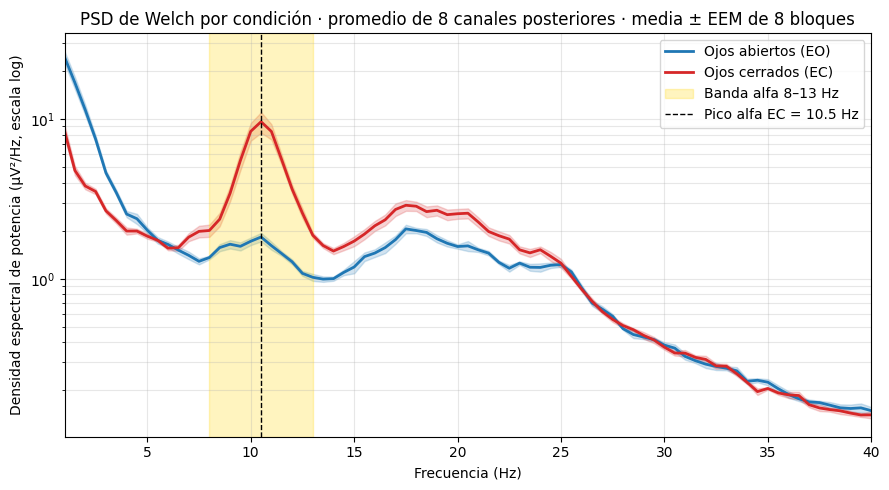

Figura guardada: /content/drive/MyDrive/alfa-eeg-data/figuras/fig03_psd_eo_vs_ec.png


PosixPath('/content/drive/MyDrive/alfa-eeg-data/figuras/fig03_psd_eo_vs_ec.png')

In [21]:
fig, ax = plt.subplots(figsize=(9, 5))
colores = {"EO": "tab:blue", "EC": "tab:red"}
etiquetas = {"EO": "Ojos abiertos (EO)", "EC": "Ojos cerrados (EC)"}

for c in ["EO", "EC"]:
    ax.semilogy(freqs, psd_media[c], color=colores[c], lw=2, label=etiquetas[c])
    ax.fill_between(freqs, psd_media[c] - psd_sem[c], psd_media[c] + psd_sem[c],
                    color=colores[c], alpha=0.2)

a, b_ = cfg["banda_alfa"]
ax.axvspan(a, b_, color="gold", alpha=0.25, label=f"Banda alfa {a:g}–{b_:g} Hz")
ax.axvline(iaf, color="k", ls="--", lw=1, label=f"Pico alfa EC = {iaf:.1f} Hz")

ax.set_xlim(1, 40)
ax.set_xlabel("Frecuencia (Hz)")
ax.set_ylabel("Densidad espectral de potencia (µV²/Hz, escala log)")
ax.set_title(f"PSD de Welch por condición · promedio de {len(canales)} canales posteriores · "
             f"media ± EEM de 8 bloques")
ax.legend()
ax.grid(alpha=0.3, which="both")
plt.tight_layout()
plt.show()

alfa.guardar_figura(fig, "fig03_psd_eo_vs_ec")

####La caida abrupta en 25 Hz proviene del registro, no del filtro aplicado. En el registro crudo tambien aparece esa caída. No la introduce nuestro acondicionamiento: es una característica de la señal, donde termina la actividad beta de este participante.

## 4. Comparación cuantitativa EO vs EC

- [ ] Valores por bloque (no solo espectros)
- [ ] Razón EC/EO por par de bloques

In [22]:
def resumen_por_bloque_local(df):
    """Una fila por bloque: media y desviación de alfa (abs y rel) y razón EC/EO del par.

    Usa solo ventanas 'dentro' (completas en el bloque, después del recorte).
    Primero promedia entre canales en cada ventana; luego resume las ventanas del bloque.
    Par = cada EC con el EO que le sigue (bloques 1-2, 3-4, …, 15-16).
    """
    d = df[df["dentro"]] if "dentro" in df else df.dropna(subset=["bloque"])
    por_ventana = (d.groupby(["bloque", "condicion", "t_s"], as_index=False)
                     [["alfa_abs", "alfa_rel"]].mean())
    res = (por_ventana.groupby(["bloque", "condicion"])
           .agg(n_ventanas=("t_s", "size"),
                alfa_abs_media=("alfa_abs", "mean"), alfa_abs_de=("alfa_abs", "std"),
                alfa_rel_media=("alfa_rel", "mean"), alfa_rel_de=("alfa_rel", "std"))
           .reset_index())
    res["par"] = (res["bloque"] + 1) // 2
    for m in ["abs", "rel"]:
        piv = res.pivot(index="par", columns="condicion", values=f"alfa_{m}_media")
        res[f"razon_ec_eo_{m}"] = res["par"].map(piv["EC"] / piv["EO"])
    return res

resumen = _usar("resumen_por_bloque", resumen_por_bloque_local, df)
resumen.to_csv(R["resultados"] / "resumen_por_bloque.csv", index=False)
display(resumen.round(3))

razones = resumen.drop_duplicates("par").set_index("par")[["razon_ec_eo_abs", "razon_ec_eo_rel"]]
print("\nRazón EC/EO por par de bloques:")
display(razones.round(2))
print(razones.agg(["mean", "std", "min", "max"]).round(2))
print(f"\nPares con EC > EO: abs {(razones['razon_ec_eo_abs'] > 1).sum()}/8 · "
      f"rel {(razones['razon_ec_eo_rel'] > 1).sum()}/8")

[provisional] alfa.resumen_por_bloque() aún no existe → uso la versión de este notebook


,bloque,condicion,n_ventanas,alfa_abs_media,alfa_abs_de,alfa_rel_media,alfa_rel_de,par,razon_ec_eo_abs,razon_ec_eo_rel
0,1,EC,53,14.544,8.352,0.235,0.079,1,1.969,1.680
1,2,EO,53,7.386,3.112,0.140,0.059,1,1.969,1.680
2,3,EC,53,18.719,15.883,0.251,0.113,2,2.642,1.905
3,4,EO,53,7.085,2.705,0.132,0.049,2,2.642,1.905
4,5,EC,53,23.259,16.211,0.287,0.110,3,3.597,2.256
5,6,EO,53,6.466,3.515,0.127,0.061,3,3.597,2.256
6,7,EC,53,27.941,14.570,0.316,0.091,4,3.609,2.156
7,8,EO,53,7.741,3.236,0.147,0.061,4,3.609,2.156
8,9,EC,53,23.266,17.055,0.283,0.099,5,2.666,1.834
9,10,EO,53,8.726,3.936,0.154,0.058,5,2.666,1.834



Razón EC/EO por par de bloques:


,razon_ec_eo_abs,razon_ec_eo_rel
par,,
1,1.97,1.68
2,2.64,1.90
3,3.60,2.26
4,3.61,2.16
5,2.67,1.83
6,3.97,2.35
7,4.92,2.44
8,4.50,2.38


      razon_ec_eo_abs  razon_ec_eo_rel
mean             3.48             2.12
std              1.00             0.28
min              1.97             1.68
max              4.92             2.44

Pares con EC > EO: abs 8/8 · rel 8/8


####El aumento del alfa al cerrar los ojos aparece en cada bloque del registro, no solo en el promedio.

In [23]:
from scipy.stats import spearmanr

ec = resumen[resumen["condicion"] == "EC"]
eo = resumen[resumen["condicion"] == "EO"]
razones_par = resumen.drop_duplicates("par")

for nombre, x, y in [("Alfa abs EC", ec["bloque"], ec["alfa_abs_media"]),
                     ("Alfa abs EO", eo["bloque"], eo["alfa_abs_media"]),
                     ("Razón EC/EO abs", razones_par["par"], razones_par["razon_ec_eo_abs"]),
                     ("Razón EC/EO rel", razones_par["par"], razones_par["razon_ec_eo_rel"])]:
    rho, p = spearmanr(x, y)
    print(f"{nombre:<16} ρ de Spearman = {rho:+.2f} (p = {p:.3f}, n = {len(x)})")

Alfa abs EC      ρ de Spearman = +0.98 (p = 0.000, n = 8)
Alfa abs EO      ρ de Spearman = +0.24 (p = 0.570, n = 8)
Razón EC/EO abs  ρ de Spearman = +0.90 (p = 0.002, n = 8)
Razón EC/EO rel  ρ de Spearman = +0.81 (p = 0.015, n = 8)


- p < 0.001, no “p = 0.000”. El 0.000 es solo redondeo de la impresión.
El ρ de 0.98 en EC sale de una sola inversión en 8 bloques: el bloque 9 (23.27) queda casi igual al bloque 5 (23.26), por debajo del bloque 7. Todo lo demás va en orden creciente.
- Como EO no tiene tendencia, el aumento de la reactividad viene de que el alfa con ojos cerrados crece, no de que el alfa con ojos abiertos baje.  Esto ayuda a descartar una deriva global de amplitud (impedancia o ganancia), que habría movido las dos condiciones.
- Limitaciones:
  - Con n = 8 bloques, los valores de p son orientativos.
  - El tiempo y el orden de los bloques no se pueden separar: el EC más tardío siempre es el último. Con este diseño no se puede saber si el efecto es por el tiempo, por la fatiga o por la repetición.
  - Es un solo participante: el hallazgo describe este registro y no se puede generalizar

## 5. Figura 4 · Alfa a lo largo del registro

- [ ] Potencia por ventana vs tiempo, bloques sombreados

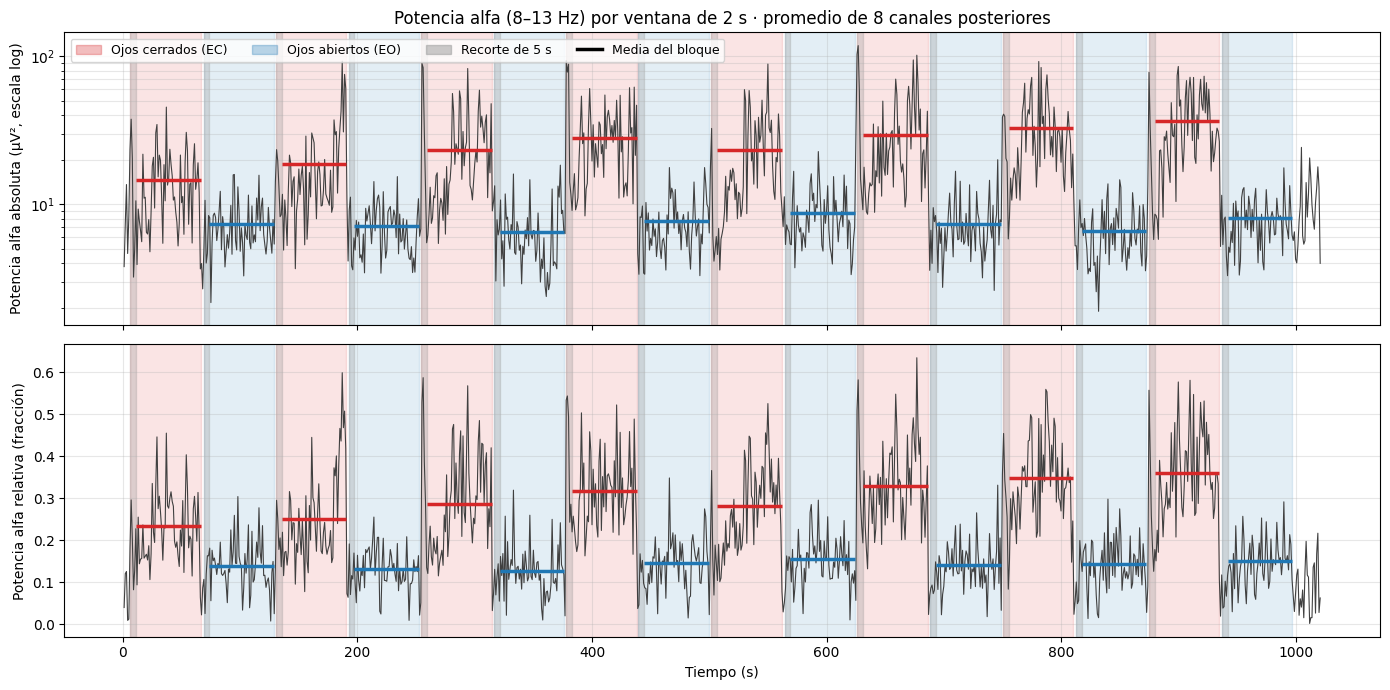

Figura guardada: /content/drive/MyDrive/alfa-eeg-data/figuras/fig04_alfa_en_el_tiempo.png


PosixPath('/content/drive/MyDrive/alfa-eeg-data/figuras/fig04_alfa_en_el_tiempo.png')

In [24]:
# Promedio entre canales por ventana (todas las ventanas, también transiciones)
serie = df.groupby("t_s", as_index=False)[["alfa_abs", "alfa_rel"]].mean()

fig, axs = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
color_cond = {"EO": "tab:blue", "EC": "tab:red"}

for ax, col, etiqueta in [(axs[0], "alfa_abs", "Potencia alfa absoluta (µV², escala log)"),
                          (axs[1], "alfa_rel", "Potencia alfa relativa (fracción)")]:
    ax.plot(serie["t_s"], serie[col], color="0.25", lw=0.8)
    for _, b in bloques.iterrows():
        ax.axvspan(b["inicio_s"], b["fin_s"], color=color_cond[b["condicion"]], alpha=0.12)
        ax.axvspan(b["inicio_s"], b["inicio_s"] + cfg["recorte_transicion_s"], color="0.6", alpha=0.3)
    for _, r in resumen.iterrows():                       # media del bloque (ventanas 'dentro')
        b = bloques.loc[bloques["bloque"] == r["bloque"]].iloc[0]
        ax.hlines(r[f"{col}_media"], b["inicio_s"] + cfg["recorte_transicion_s"], b["fin_s"],
                  color=color_cond[r["condicion"]], lw=2.5)
    ax.set_ylabel(etiqueta)
    ax.grid(alpha=0.3, which="both")
axs[0].set_yscale("log")

from matplotlib.patches import Patch
from matplotlib.lines import Line2D
axs[0].legend(handles=[Patch(color="tab:red", alpha=0.3, label="Ojos cerrados (EC)"),
                       Patch(color="tab:blue", alpha=0.3, label="Ojos abiertos (EO)"),
                       Patch(color="0.6", alpha=0.5, label=f"Recorte de {cfg['recorte_transicion_s']:g} s"),
                       Line2D([], [], color="k", lw=2.5, label="Media del bloque")],
              loc="upper left", ncol=4, fontsize=9)
axs[1].set_xlabel("Tiempo (s)")
axs[0].set_title(f"Potencia alfa ({cfg['banda_alfa'][0]:g}–{cfg['banda_alfa'][1]:g} Hz) por ventana de "
                 f"{cfg['ventana_s']:g} s · promedio de {len(cfg['canales'])} canales posteriores")
plt.tight_layout()
plt.show()

alfa.guardar_figura(fig, "fig04_alfa_en_el_tiempo")

## 6. Transiciones

- [ ] Curva promedio alrededor de cada cambio EO→EC y EC→EO
- [ ] ¿El cambio aparece igual después de cada transición? ¿Cuánto tarda?

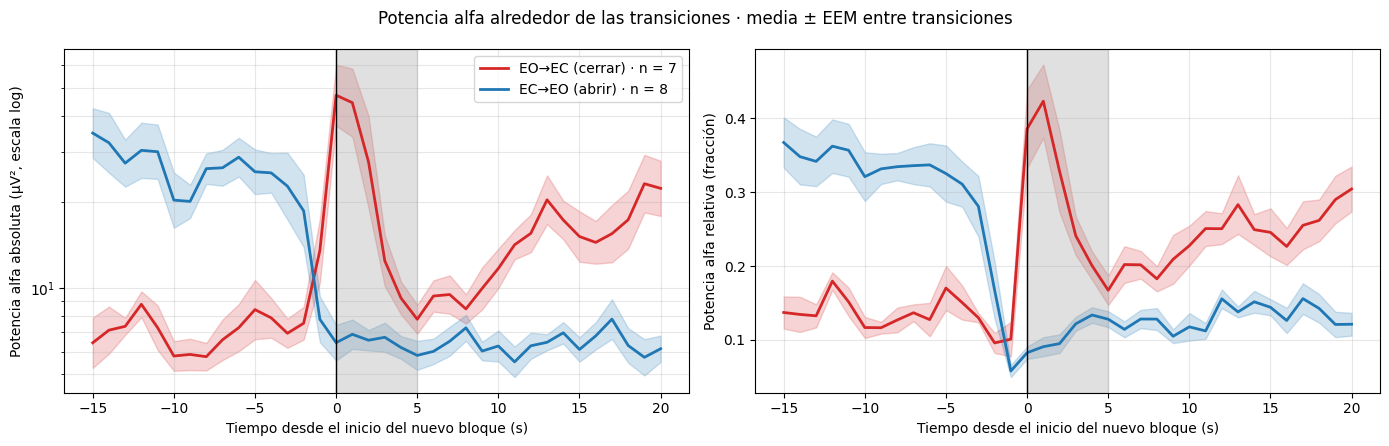

Figura guardada: /content/drive/MyDrive/alfa-eeg-data/figuras/fig04b_transiciones.png


,transicion,inicio_s,cambio_x,latencia_s
0,EO→EC (cerrar),130.5,1.82,-1.0
1,EO→EC (cerrar),254.4,1.90,-2.0
2,EO→EC (cerrar),378.0,2.47,0.0
3,EO→EC (cerrar),501.7,0.94,-2.0
4,EO→EC (cerrar),626.3,1.94,-2.0
5,EO→EC (cerrar),750.3,1.88,-1.0
6,EO→EC (cerrar),874.9,2.52,-1.0
7,EC→EO (abrir),68.7,0.60,-2.0
8,EC→EO (abrir),192.4,0.15,-1.0
9,EC→EO (abrir),316.2,0.23,-1.0


               cambio_x             latencia_s          
                 median   min   max     median  min  max
transicion                                              
EC→EO (abrir)      0.24  0.15  0.60       -1.0 -2.0  0.0
EO→EC (cerrar)     1.90  0.94  2.52       -1.0 -2.0  0.0


In [25]:
# TODO
# ── Curva promedio alrededor de cada transición ──────────────────────────
pre, post = 15, 20
grid = np.arange(-pre, post + 1, 1.0)           # resolución de 1 s (una ventana por segundo)

def tramo(t0, col):
    y = np.interp(t0 + grid, serie["t_s"], serie[col], left=np.nan, right=np.nan)
    return np.log10(y) if col == "alfa_abs" else y   # la absoluta se promedia en log

transiciones = {
    "EO→EC (cerrar)": bloques[(bloques["condicion"] == "EC") & (bloques["bloque"] > 1)],
    "EC→EO (abrir)":  bloques[bloques["condicion"] == "EO"],
}
color_t = {"EO→EC (cerrar)": "tab:red", "EC→EO (abrir)": "tab:blue"}

fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
latencias = []
for ax, col, etiqueta in [(axs[0], "alfa_abs", "Potencia alfa absoluta (µV², escala log)"),
                          (axs[1], "alfa_rel", "Potencia alfa relativa (fracción)")]:
    for nombre, bl in transiciones.items():
        M = np.array([tramo(t0, col) for t0 in bl["inicio_s"]])          # (transiciones, tiempo)
        media = np.nanmean(M, axis=0)
        eem = np.nanstd(M, axis=0, ddof=1) / np.sqrt(len(M))
        f = (lambda v: 10**v) if col == "alfa_abs" else (lambda v: v)
        ax.plot(grid, f(media), color=color_t[nombre], lw=2, label=f"{nombre} · n = {len(M)}")
        ax.fill_between(grid, f(media - eem), f(media + eem), color=color_t[nombre], alpha=0.2)

        if col == "alfa_abs":                                             # latencia por transición
            for t0, curva in zip(bl["inicio_s"], M):
                antes = np.nanmean(curva[(grid >= -10) & (grid <= -2)])
                despues = np.nanmean(curva[(grid >= 6) & (grid <= 15)])
                medio = (antes + despues) / 2
                cruza = (curva >= medio) if despues > antes else (curva <= medio)
                idx = np.where(cruza & (grid >= -2))[0]
                latencias.append({"transicion": nombre, "inicio_s": round(t0, 1),
                                  "cambio_x": round(10**(despues - antes), 2),
                                  "latencia_s": grid[idx[0]] if len(idx) else np.nan})
    ax.axvline(0, color="k", lw=1)
    ax.axvspan(0, cfg["recorte_transicion_s"], color="0.6", alpha=0.3)
    ax.set_xlabel("Tiempo desde el inicio del nuevo bloque (s)")
    ax.set_ylabel(etiqueta)
    ax.grid(alpha=0.3, which="both")
axs[0].set_yscale("log")
axs[0].legend()
fig.suptitle("Potencia alfa alrededor de las transiciones · media ± EEM entre transiciones")
plt.tight_layout()
plt.show()
alfa.guardar_figura(fig, "fig04b_transiciones")

lat = pd.DataFrame(latencias)
display(lat)
print(lat.groupby("transicion")[["cambio_x", "latencia_s"]].agg(["median", "min", "max"]))

Al abrir los ojos el EC se vuelve EO; mientras que al cerrar los ojos el EO se vuelve EC.  
Hay una asimetría: abrir los ojos apaga el alfa rápido y por completo. Cerrarlos lo recupera de golpe por un momento, pero el nivel estable tarda más de 15 s en alcanzarse

## 7. Figura 5 · Comparación entre bloques

- [ ] Boxplot o puntos por bloque, EO y EC lado a lado
- [ ] Bloques que se apartan del comportamiento general y posibles causas

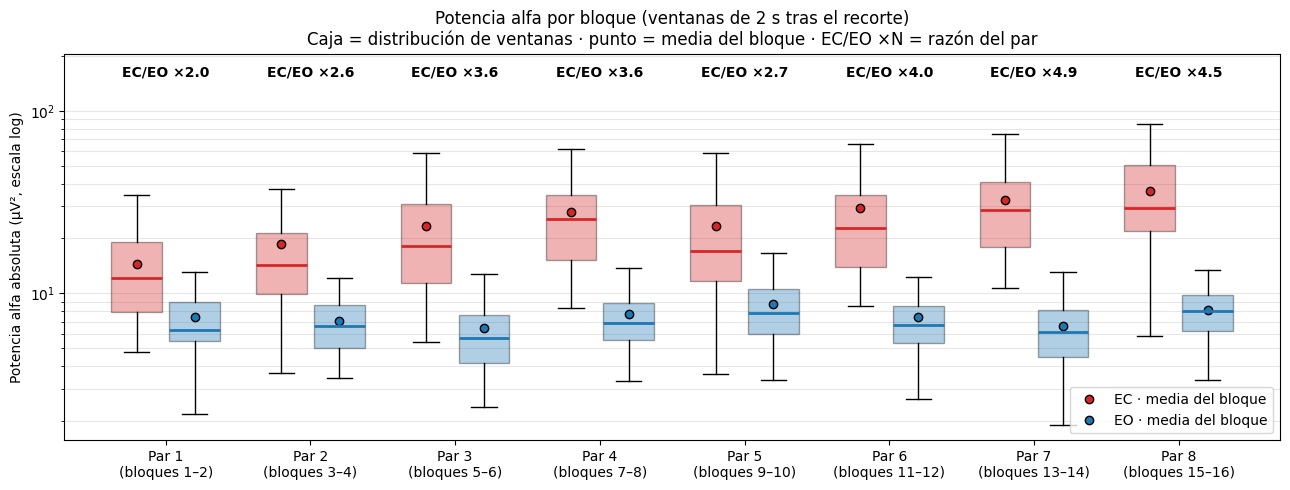

Figura guardada: /content/drive/MyDrive/alfa-eeg-data/figuras/fig05_comparacion_bloques.png


PosixPath('/content/drive/MyDrive/alfa-eeg-data/figuras/fig05_comparacion_bloques.png')

In [26]:
# alfa.guardar_figura(fig, "fig05_comparacion_bloques")
d = df[df["dentro"]].groupby(["bloque", "condicion", "t_s"], as_index=False)["alfa_abs"].mean()
d["par"] = (d["bloque"] + 1) // 2

fig, ax = plt.subplots(figsize=(13, 5))
desplaz = {"EC": -0.2, "EO": 0.2}
for c in ["EC", "EO"]:
    datos = [d[(d["par"] == p) & (d["condicion"] == c)]["alfa_abs"].values for p in range(1, 9)]
    pos = np.arange(1, 9) + desplaz[c]
    bp = ax.boxplot(datos, positions=pos, widths=0.35, patch_artist=True, showfliers=False)
    for caja in bp["boxes"]:
        caja.set(facecolor=color_cond[c], alpha=0.35)
    for m in bp["medians"]:
        m.set(color=color_cond[c], lw=2)
    medias = resumen[resumen["condicion"] == c].sort_values("par")["alfa_abs_media"].values
    ax.plot(pos, medias, "o", color=color_cond[c], mec="k", label=f"{c} · media del bloque")

ax.set_yscale("log")
ax.set_ylim(top=ax.get_ylim()[1] * 2)          # deja espacio arriba para las etiquetas
for p, r in zip(razones_par["par"], razones_par["razon_ec_eo_abs"]):
    ax.text(p, 0.97, f"EC/EO ×{r:.1f}", transform=ax.get_xaxis_transform(),
            ha="center", va="top", fontsize=10, fontweight="bold")

ax.set_xticks(range(1, 9))
ax.set_xticklabels([f"Par {p}\n(bloques {2*p-1}–{2*p})" for p in range(1, 9)])
ax.set_ylabel("Potencia alfa absoluta (µV², escala log)")
ax.set_title("Potencia alfa por bloque (ventanas de 2 s tras el recorte)\n"
             "Caja = distribución de ventanas · punto = media del bloque · EC/EO ×N = razón del par")
ax.legend(loc="lower right")
ax.grid(alpha=0.3, which="both", axis="y")
plt.tight_layout()
plt.show()
alfa.guardar_figura(fig, "fig05_comparacion_bloques")

## Interpretación breve

**Observaciones**

- **Reactividad alfa clara y consistente.** Con ojos cerrados aparece un pico espectral en **10.5 Hz** (pico alfa individual), ~5 veces más alto que con ojos abiertos. La potencia absoluta en 8–13 Hz es mayor en EC que en EO en los **8 de 8 pares** de bloques, con una razón EC/EO media de **3.5** (rango 2.0–4.9). La potencia relativa da la misma conclusión (razón media 2.1, rango 1.7–2.4).
- **La reactividad aumenta a lo largo del registro.** La potencia alfa en EC crece casi de forma monótona entre bloques (ρ de Spearman = +0.98, p < 0.001, n = 8), mientras que en EO se mantiene estable (ρ = +0.24, p = 0.57). En consecuencia, la razón EC/EO también aumenta (ρ = +0.90). La única excepción es el bloque 9, cuyo alfa en EC es menor que el del bloque anterior.
- **Dinámica asimétrica en las transiciones.** Al abrir los ojos, el alfa cae a ~1/4 de su nivel en 1–2 s. Al cerrarlos aparece un aumento breve e intenso en el primer segundo, seguido de una caída y de una recuperación gradual que no se estabiliza antes de ~15–20 s.
- **Variabilidad dentro de los bloques.** En EC, la potencia alfa fluctúa mucho entre ventanas (aparece en ráfagas); a nivel de ventanas individuales de 2 s, las distribuciones de EC y EO se traslapan, aunque las medias por bloque se separan claramente.

**Interpretación**

El aumento de la potencia alfa al cerrar los ojos en regiones posteriores es consistente con el efecto de Berger descrito en la literatura. El crecimiento progresivo del alfa en EC podría relacionarse con cambios en el estado de relajación o de vigilancia durante el registro, pero los datos no permiten identificar la causa. Como la potencia en EO no cambia, es poco probable que el aumento se deba a una deriva global de la amplitud de la señal.

**Limitaciones**

Se trata de un solo participante y de 8 pares de bloques, por lo que los valores de p son orientativos y los resultados no se pueden generalizar. El orden temporal de los bloques no se puede separar de efectos de repetición o fatiga. Las latencias de las transiciones tienen una resolución de ~1–2 s por el tamaño de la ventana y porque el marcador del bloque no coincide necesariamente con el momento real de abrir o cerrar los ojos. La lenta recuperación del alfa tras cerrar los ojos indica que el recorte de 5 s no captura el estado estable, por lo que las medias de EC dependen del recorte elegido (se evalúa en la etapa de robustez).